# 02 — So sánh sản xuất gạo theo FAOSTAT source areas

Comparator universe: India, Indonesia, Viet Nam, Thailand theo exact source M49 identities; không world ranking/total.

Environment: Windows host, Python 3.10–3.13; `pip install -r requirements/analytics.txt`.
Docker `tlcn-local` đã healthy, Windows available >=2 GiB, WSL >=3 GiB, không active writer/DagRun.
Không start Spark. Mỗi notebook chạy độc lập, theo thứ tự cells. Query names/typed filters hiển thị
trong retrieval cells; kết quả là full scoped results/aggregates, **không phải 20-row sample consumer**.
Source-scoped identities không phải official crosswalk. Không forward-fill/interpolate.

Chạy `python scripts/run_eda_notebooks.py --notebook <filename>` từ repo root để execute và cập nhật
Markdown diễn giải bằng đúng measured evidence. Kết quả Markdown ghi batch cố định bên trên;
publication đổi sẽ fail closed. Không dùng outputs cũ như live query cache.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/gold/consumer.py').exists())
sys.path.insert(0, str(ROOT/'src'))  # repository bootstrap, no credentials
import pandas as pd
import numpy as np
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from analytics.client import EDAClient
from analytics.methods import calendar_yoy, endpoint_change, monthly_calendar
from analytics.notebook import inspect_frame, label, resolve, annual_plot, save_evidence
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
client = EDAClient()
findings = []
inventory = client.query('publication')
EXPECTED_BATCH = 'ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235'
assert client.batch == EXPECTED_BATCH, 'Publication changed: review scope before reproducing EDA'
display(inventory)
print('Published batch:', client.batch, '| No query cache | Windows/WSL/writer gates checked per request')

,table,rows,uuid,snapshot_id
0,dim_date,2038,0d029553-197b-4e46-8d62-17f21334a11b,7665947661409225898
1,dim_month,800,4f262a83-5e36-4d9e-b7e0-18f91b46327f,8295574410069434036
2,dim_observation_type,34,8adc0a9f-498e-4503-aa05-f95ae5a358ed,1046146616745412073
3,dim_price_series,1042,fa39bf1e-bbf1-4b50-8129-de1d4f37413b,2896601742107309180
4,dim_source_geography,987,ce487b86-5541-44de-a006-365dfbcc29f2,8664595598201008097
5,dim_source_product,295,4ce4f42f-e876-4870-8b2a-0312c460d673,8514812747103222137
6,dim_source_system,9,3c9fdb0f-127a-45f4-8f5b-31c7d1d5c0c1,5212267582300439758
7,dim_year,67,032861f7-4c4e-4ac4-9a10-274670b1d694,3316235776078407392
8,fact_fao_price_annual,9993,3218dd14-0793-4c1d-941c-31ba5e1aaea8,6561274137596983252
9,fact_fao_production_observation,22738,f97e800f-ebe6-416c-918a-a148ec0388b4,4557995850181557281


Published batch: ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235 | No query cache | Windows/WSL/writer gates checked per request


## Câu hỏi 1 — Production, area và paired yield của bốn source areas?

In [2]:
geos=client.query('catalogue',kind='geographies');products=client.query('catalogue',kind='products')
identities=['356','360','704','764']  # observed catalogue codes, not a cross-provider conversion
keys=[resolve(geos,'faostat_m49',i,'geography_key') for i in identities]
product=resolve(products,'faostat_cpc','0113','product_key')
df=client.query('fao_production',geographies=keys,product=product,start_year=1961,end_year=2024)

In [3]:
display(df.shape,inspect_frame(df),df.head())

(256, 20)

,dtype,nulls
year_key,int64,0
geography_key,object,0
product_key,object,0
area_ha,object,0
present_5312,int64,0
observation_5312,object,0
production_t,object,0
present_5510,int64,0
observation_5510,object,0
reported_yield_kg_ha,object,0


,year_key,geography_key,product_key,area_ha,present_5312,observation_5312,production_t,present_5510,observation_5510,reported_yield_kg_ha,present_5412,observation_5412,computed_yield_kg_ha,geography_identity,geography_labels,product_identity,product_labels,production_source_flag,area_source_flag,reported_yield_source_flag
0,1981,256f554cdf117a037270266ee412d64bdcf4ebdc09e03c...,47b4dde0c6083d0e2ee5a313603df027c7c03d6ef2f46f...,9381839.00,1,ea8fe338b626a21c353811dd6f1aa088d4c5b05398e366...,32774176.00,1,c7c89b7321f90079eccf49ea663c68365ee0b128fd2b72...,3493.40,1,bdaffbd647a64a242e3839d21f3a577bdadafdf396a192...,3493.364,360,"[{""label"":""Indonesia"",""role"":""source""}]",0113,"[""Rice""]",A,A,A
1,1981,454338b3e9b9203015ec55fa27305ffba31eac866ae497...,47b4dde0c6083d0e2ee5a313603df027c7c03d6ef2f46f...,5651900.00,1,59cac1f72f76ef079e81a4ac6c714a609af54d3bbb7327...,12415200.00,1,cc1a209b9f53f7e1740f5e8da3c99225fe2d62ec622391...,2196.60,1,a13e26cf0913867e4255c17e58b829f2880dfbc94e196d...,2196.642,704,"[{""label"":""Viet Nam"",""role"":""source""}]",0113,"[""Rice""]",A,A,A
2,1982,c087e1348e72dc9aff782ecac286c3a18c9414ca280dc9...,47b4dde0c6083d0e2ee5a313603df027c7c03d6ef2f46f...,38262000.00,1,f66b291c9cad90e058a4477f8c299b3772e8b90645a15d...,70771696.00,1,f7ee2ff72baa99807218e6a2e8710cfecf3f867c1753f7...,1849.70,1,6f1136a5b07fc645470f15c8737fabed6292dc921377ed...,1849.660,356,"[{""label"":""India"",""role"":""source""}]",0113,"[""Rice""]",A,A,A
3,1982,454338b3e9b9203015ec55fa27305ffba31eac866ae497...,47b4dde0c6083d0e2ee5a313603df027c7c03d6ef2f46f...,5711700.00,1,d1b4c2eca91ac3f3a2a83c233df59c5341a20759f0b3ea...,14390200.00,1,5ab9a5ea734ed42ebf4a9ec676a02ea3d12cedeed7e9de...,2519.40,1,270df1939d5c54098575562e6663d9152f1ff0c429e59a...,2519.425,704,"[{""label"":""Viet Nam"",""role"":""source""}]",0113,"[""Rice""]",A,A,A
4,1983,256f554cdf117a037270266ee412d64bdcf4ebdc09e03c...,47b4dde0c6083d0e2ee5a313603df027c7c03d6ef2f46f...,9162469.00,1,362091c2381aa14aabe2a41f4338a9ede841845bcdf173...,35303008.00,1,1e38f494c2b551d7c18321d090604400f20394d223501b...,3853.00,1,9174d267866ce282143906f6cb4c359078da665956a6ab...,3853.002,360,"[{""label"":""Indonesia"",""role"":""source""}]",0113,"[""Rice""]",A,A,A


In [4]:
for col in ['production_t','area_ha','reported_yield_kg_ha','computed_yield_kg_ha']:df[col]=pd.to_numeric(df[col])
assert not df.duplicated(['geography_key','product_key','year_key']).any()
assert all((df[c]<=1).all() for c in ['present_5312','present_5510','present_5412'])
df['source_area']=df.geography_labels.map(label)
paired=df.production_t.notna()&df.area_ha.gt(0)
np.testing.assert_allclose(df.loc[paired,'computed_yield_kg_ha'],1000*df.loc[paired,'production_t']/df.loc[paired,'area_ha'],rtol=1e-4)

In [5]:
display(df.groupby('source_area')[['production_t','area_ha','computed_yield_kg_ha']].describe())

production_t                                                      \
                   count          mean           std         min         25%   
source_area                                                                    
India               64.0  1.122944e+08  4.517235e+07  45657008.0  69598024.0   
Indonesia           64.0  4.058258e+07  1.627908e+07  11595000.0  23335588.0   
Thailand            64.0  2.264019e+07  8.277490e+06  10150000.0  15242000.0   
Viet Nam            64.0  2.488779e+07  1.360822e+07   8366150.0  11099572.5   

                                                     area_ha                \
                     50%           75%           max   count          mean   
source_area                                                                  
India        111515279.0  1.414639e+08  2.178679e+08    64.0  4.148007e+07   
Indonesia     47411294.0  5.421715e+07  6.103100e+07    64.0  1.001360e+07   
Thailand      20432440.0  3.007125e+07  3.946925e+07    64.0  9.257001e+06   
Viet Nam      22213452.0  3.878490e+07  4.509056e+07    64.0  6.342817e+06   

             ...                          computed_yield_kg_ha               \
             ...          75%         max                count         mean   
source_area  ...                                                              
India        ...  43685649.75  50511930.0                 64.0  2643.228453   
Indonesia    ...  11483017.75  11963204.0                 64.0  3887.852719   
Thailand     ...  10201080.00  12278889.0                 64.0  2371.576281   
Viet Nam     ...   7439225.00   7902813.0                 64.0  3679.135453   

                                                                       \
                     std       min         25%        50%         75%   
source_area                                                             
India         887.003386  1293.586  1818.72600  2624.3270  3282.87525   
Indonesia    1168.721941  1722.627  2790.71650  4323.2105  4937.26500   
Thailand      513.375481  1590.971  1887.93475  2212.6920  2929.44925   
Viet Nam     1521.871930  1709.541  2184.22975  3407.8555  5234.51450   

                       
                  max  
source_area            
India        4313.525  
Indonesia    5358.767  
Thailand     3214.399  
Viet Nam     6151.656  

[4 rows x 24 columns]

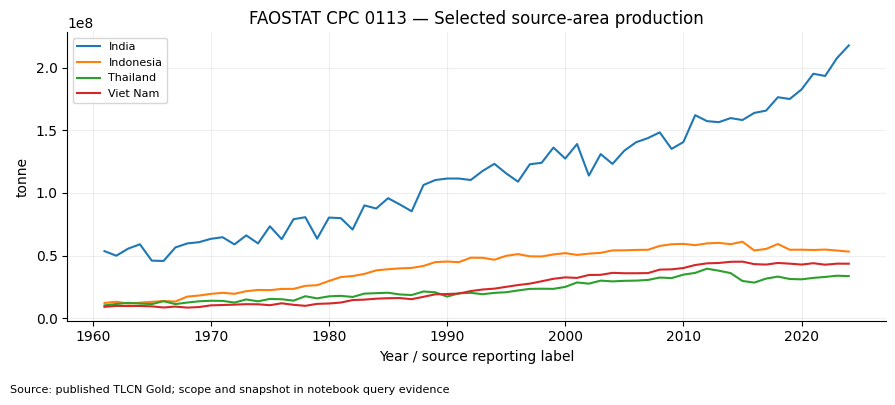

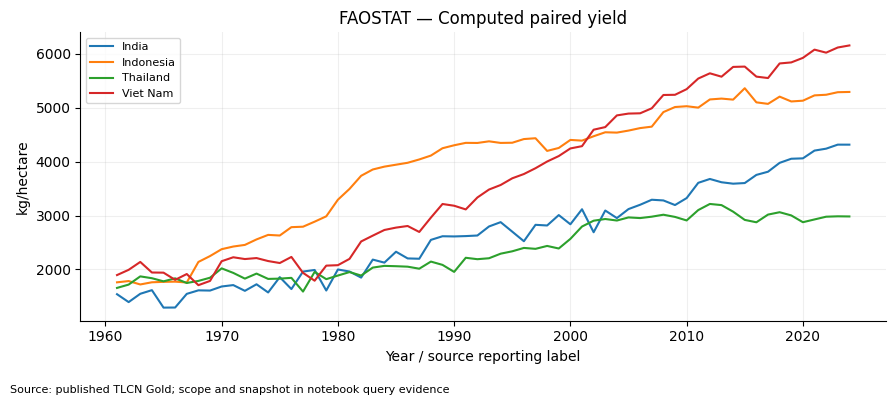

In [6]:
annual_plot(df,'production_t','FAOSTAT CPC 0113 — Selected source-area production','tonne',group='source_area')
annual_plot(df,'computed_yield_kg_ha','FAOSTAT — Computed paired yield','kg/hectare',group='source_area')

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Chỉ cùng source product 0113 và metric 5510/5312. Không gộp paddy với milled hoặc nguồn khác.

In [7]:
stats=pd.DataFrame([dict(source_area=a,**endpoint_change(d,value='production_t')) for a,d in df.groupby('source_area')])
display(stats)
vn=df[df.geography_identity=='704']
production_change=endpoint_change(vn,value='production_t');area_change=endpoint_change(vn,value='area_ha');yield_change=endpoint_change(vn,value='computed_yield_kg_ha')
findings.append(dict(id='FAO01',title='Production, area và computed yield của Viet Nam',observation=f"{production_change['first_year']}–{production_change['last_year']}: production {production_change['change_pct']:+.2f}%, harvested area {area_change['change_pct']:+.2f}%, computed paired yield {yield_change['change_pct']:+.2f}%.",scope='FAOSTAT M49 704 / CPC 0113; source quantity metrics',interpretation='Accounting association của production/area; derived yield không là independent causal explanation.',query='fao_production',cell='Câu hỏi 1',numbers=dict(production=production_change,area=area_change,yield_change=yield_change)))
yield_changes=pd.DataFrame([dict(source_area=a,**endpoint_change(d,value='computed_yield_kg_ha')) for a,d in df.groupby('source_area')])
display(yield_changes)
best=yield_changes.sort_values('change_pct',ascending=False).iloc[0]
findings.append(dict(id='FAO02',title='Thay đổi computed yield trong selected universe',observation=f"{best.source_area}: {best.first_value:,.2f} → {best.last_value:,.2f} kg/ha ({best.change_pct:+.2f}%, {int(best.first_year)}–{int(best.last_year)}).",scope='Four explicitly selected FAOSTAT source areas; CPC 0113, paired measures',interpretation='Largest proportional change among selected endpoints, not global best performance.',query='fao_production',cell='Câu hỏi 1',numbers=yield_changes.to_dict(orient='records')))

,source_area,first_year,last_year,first_value,last_value,change_pct,cagr_pct,numeric_periods,calendar_span
0,India,1961,2024,53494496.0,2.178679e+08,307.271552,2.254093,64,64
1,Indonesia,1961,2024,12084000.0,5.314273e+07,339.777615,2.378803,64,64
2,Thailand,1961,2024,10150000.0,3.355134e+07,230.555041,1.915905,64,64
3,Viet Nam,1961,2024,8997400.0,4.345045e+07,382.922278,2.531000,64,64


,source_area,first_year,last_year,first_value,last_value,change_pct,cagr_pct,numeric_periods,calendar_span
0,India,1961,2024,1541.895,4313.196,179.733445,1.646208,64,64
1,Indonesia,1961,2024,1762.287,5289.868,200.170631,1.760041,64,64
2,Thailand,1961,2024,1658.497,2982.723,79.844944,0.935980,64,64
3,Viet Nam,1961,2024,1896.585,6151.656,224.354353,1.885276,64,64


## Câu hỏi 2 — Common-year ranking và area/yield association

In [8]:
common=set.intersection(*[set(d.loc[d.production_t.notna()&d.area_ha.gt(0),'year_key']) for _,d in df.groupby('source_area')])
assert common,'No common paired comparison year'
year=max(common);rank=df[df.year_key==year].sort_values('production_t',ascending=False)
growth=calendar_yoy(df,['geography_key','product_key'],value='production_t')
display(rank[['source_area','year_key','production_t','area_ha','computed_yield_kg_ha']],growth[['source_area','year_key','yoy_pct']].tail())
leader=rank.iloc[0]
findings.append(dict(id='FAO03',title='Common-year ranking trong bốn source areas',observation=f"Năm {year}, {leader.source_area} có {leader.production_t:,.0f} tonnes, cao nhất trong bốn source areas được chọn.",scope='Exact four-area comparator universe, common numeric year, CPC 0113',interpretation='Không phải world ranking và không chứng minh verified global total.',query='fao_production',cell='Câu hỏi 2',numbers=rank[['source_area','year_key','production_t','area_ha','computed_yield_kg_ha']].to_dict(orient='records')))

,source_area,year_key,production_t,area_ha,computed_yield_kg_ha
49,India,2024,2.178679e+08,50511930.0,4313.196
50,Indonesia,2024,5.314273e+07,10046135.0,5289.868
178,Viet Nam,2024,4.345045e+07,7063212.0,6151.656
51,Thailand,2024,3.355134e+07,11248558.0,2982.723


,source_area,year_key,yoy_pct
251,Indonesia,1994,-3.195420
252,Indonesia,1995,6.652102
253,Viet Nam,1995,6.100738
254,Thailand,1995,2.752795
255,India,1996,-5.755838


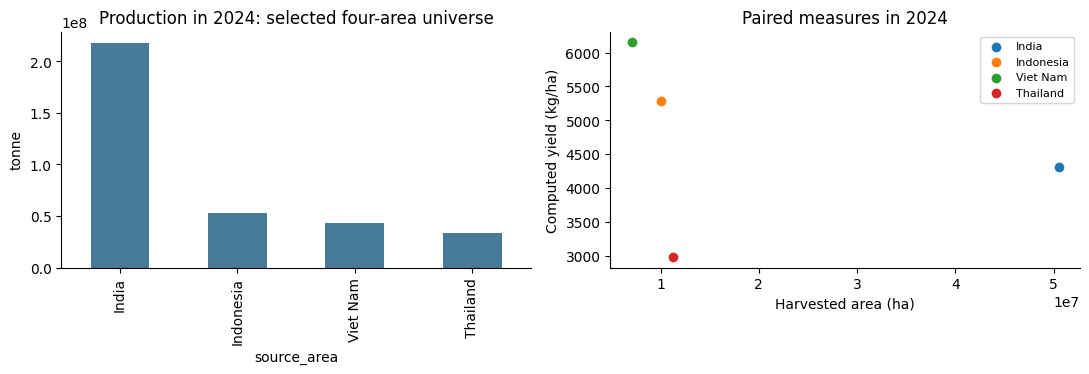

In [9]:
fig,axes=plt.subplots(1,2,figsize=(11,4));rank.set_index('source_area').production_t.plot.bar(ax=axes[0],color='#477998',title=f'Production in {year}: selected four-area universe',ylabel='tonne')
for row in rank.itertuples():axes[1].scatter(row.area_ha,row.computed_yield_kg_ha,label=row.source_area)
axes[1].set(xlabel='Harvested area (ha)',ylabel='Computed yield (kg/ha)',title=f'Paired measures in {year}');axes[1].legend(fontsize=8)
fig.tight_layout();plt.show();plt.close(fig)

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Ranking chỉ trong bốn source areas đã chọn. Không tính global total khi membership aggregate/country chưa có crosswalk chứng minh. Weighted yield, nếu dùng, phải ratio-of-sums trên paired non-overlapping population; notebook không tự chứng nhận global population.

## Key Findings

Measured batch `ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235`.

### FAO01 — Production, area và computed yield của Viet Nam

**OBSERVATION:** 1961–2024: production +382.92%, harvested area +48.89%, computed paired yield +224.35%.

**Scope:** FAOSTAT M49 704 / CPC 0113; source quantity metrics

**INTERPRETATION / LIMITATION:** Accounting association của production/area; derived yield không là independent causal explanation.

**Reproduce:** query `fao_production`, Câu hỏi 1.

### FAO02 — Thay đổi computed yield trong selected universe

**OBSERVATION:** Viet Nam: 1,896.59 → 6,151.66 kg/ha (+224.35%, 1961–2024).

**Scope:** Four explicitly selected FAOSTAT source areas; CPC 0113, paired measures

**INTERPRETATION / LIMITATION:** Largest proportional change among selected endpoints, not global best performance.

**Reproduce:** query `fao_production`, Câu hỏi 1.

### FAO03 — Common-year ranking trong bốn source areas

**OBSERVATION:** Năm 2024, India có 217,867,864 tonnes, cao nhất trong bốn source areas được chọn.

**Scope:** Exact four-area comparator universe, common numeric year, CPC 0113

**INTERPRETATION / LIMITATION:** Không phải world ranking và không chứng minh verified global total.

**Reproduce:** query `fao_production`, Câu hỏi 2.

## Limitations

FAOSTAT source_level chỉ là source_area; chưa có universal atomic/aggregate classifier. Không dùng nhãn hiển thị để join USDA/NSO; không world total, country share toàn cầu hoặc causal attribution.

In [10]:
print(save_evidence(ROOT, '02_global_rice_production', client, findings))
print('Query audit:')
display(pd.DataFrame(client.evidence)[['query','row_count','query_seconds','response_bytes','batch']])

docs/analytics/evidence/02_global_rice_production.json
Query audit:


,query,row_count,query_seconds,response_bytes,batch
0,publication,17,0.000000,4333,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
1,catalogue,987,0.122524,280735,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
2,catalogue,295,0.067826,49096,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
3,fao_production,256,1.034859,134832,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
